# Fate bias versus population abundance

## The question

**Does a larger cell population necessarily indicate greater commitment toward it?**

A treatment can change the number of recovered cells in a branch through expansion, depletion, survival or sampling. A larger branch can therefore look more prominent without demonstrating a changed fate decision at its root. This notebook asks whether root affinity and sampled branch abundance can distinguish some of those scenarios in a controlled graph.

We vary the density of sampled points while retaining prescribed velocity directions. The scenario names describe expansion-like and depletion-like sampling patterns; the simulator does not mechanistically generate proliferation or death. The abundance readout counts all sampled cells in A and B, not only their terminal anchors.

## How to read the experiment

Compare each scenario with the control across independently seeded realizations. A useful result is a smaller response of CFA than of abundance under a density-only perturbation, together with sensitivity to a changed entry-density ratio. Also inspect deviations from the nominal reference and variation across seeds: complete density invariance and an unbiased estimate of a biological branching probability are not assumed.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation import experiments as exp

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Question and simulation design
Does an expanded sampled branch necessarily imply increased root affinity toward that fate? We reproduce a prescribed-vector fork simulation with control, expansion from branch entry, downstream expansion, depletion, and a changed nominal entry-density ratio.

The generator changes sampling density along a synthetic manifold with prescribed vectors. Its nominal entry share is a generative reference, not an independently measured cell fate. It does **not** simulate cell division, death kinetics, cell-cycle effects on RNA velocity, or real splicing counts. Twenty independently seeded realizations are used per scenario. Late anchors (q=0.9) are compared with near-entry anchors (q=0.01); choosing early anchors changes the scientific question.


In [3]:
abundance = exp.proliferation(n_seeds=20)
summary = abundance.groupby(["scenario", "q"])[
    ["CFA_A", "abundance_A", "nominal_entry_share", "coverage"]
].agg(["mean", "std"])
display(summary)
abundance.to_csv(OUT / "abundance_stress_test.csv", index=False)

CFA_A            ... coverage     
                                      mean       std  ...     mean  std
scenario                    q                         ...              
A downstream expansion      0.01  0.467619  0.082731  ...      1.0  0.0
                            0.90  0.468272  0.085076  ...      1.0  0.0
A expansion from entry      0.01  0.527230  0.092469  ...      1.0  0.0
                            0.90  0.539831  0.088362  ...      1.0  0.0
B depletion from entry      0.01  0.495771  0.123252  ...      1.0  0.0
                            0.90  0.514000  0.132618  ...      1.0  0.0
Changed entry density 60/40 0.01  0.558444  0.080114  ...      1.0  0.0
                            0.90  0.597230  0.073789  ...      1.0  0.0
Control                     0.01  0.454136  0.079023  ...      1.0  0.0
                            0.90  0.457312  0.088249  ...      1.0  0.0

[10 rows x 8 columns]

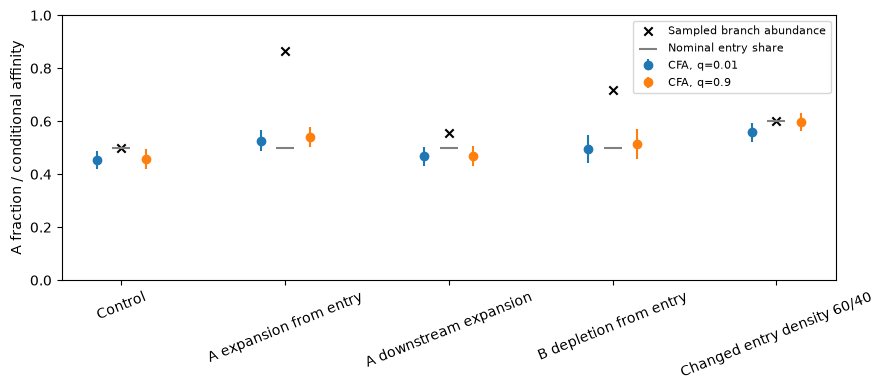

In [4]:
names = list(abundance.scenario.unique())
fig, ax = plt.subplots(figsize=(9, 4))
for q, shift in [(0.01, -0.15), (0.9, 0.15)]:
    group = (
        abundance[abundance.q == q].groupby("scenario").CFA_A.agg(["mean", "sem"]).reindex(names)
    )
    ax.errorbar(
        np.arange(len(names)) + shift,
        group["mean"],
        yerr=1.96 * group["sem"],
        marker="o",
        linestyle="none",
        label=f"CFA, q={q}",
    )
reference = (
    abundance[abundance.q == 0.01]
    .groupby("scenario")[["abundance_A", "nominal_entry_share"]]
    .mean()
    .reindex(names)
)
ax.scatter(
    np.arange(len(names)),
    reference.abundance_A,
    marker="x",
    color="black",
    label="Sampled branch abundance",
)
ax.scatter(
    np.arange(len(names)),
    reference.nominal_entry_share,
    marker="_",
    s=180,
    color="0.5",
    label="Nominal entry share",
)
ax.set(
    xticks=np.arange(len(names)),
    xticklabels=names,
    ylabel="A fraction / conditional affinity",
    ylim=(0, 1),
)
ax.tick_params(axis="x", rotation=22)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Interpretation
Read the observed table rather than assuming complete robustness: the graph kernel still depends on sampled density. Error bars quantify Monte Carlo uncertainty over synthetic realizations; they are not clinical confidence intervals. A comparison with sampled branch abundance tests a different quantity, so disagreement alone does not prove that one measure is biologically correct. Independent lineage or perturbation evidence remains necessary.


In [5]:
entry = abundance[abundance.q == 0.01].groupby("scenario")[["CFA_A", "abundance_A"]].mean()
assert entry.loc["A expansion from entry", "abundance_A"] > 0.75
assert abs(entry.loc["A expansion from entry", "CFA_A"] - 0.5) < 0.15
assert entry.loc["Changed entry density 60/40", "CFA_A"] > entry.loc["Control", "CFA_A"]
print("Predeclared qualitative density-stress checks passed.")

Predeclared qualitative density-stress checks passed.
